# Notebook 2: Composite Risk Index, Hotspot Analysis & Road Accessibility

This notebook picks up from Notebook 1 and runs through the core analysis in four stages:

1. Combine all indicators into a composite flood risk score per building
2. Find hotspot clusters of high-risk housing using KDE and Getis-Ord Gi*
3. Simulate a flood scenario and check which housing areas lose road access to universities
4. Produce static maps and an interactive Folium web map

> **Note:** Run this notebook only after `01_osm_data_pull.ipynb` has completed successfully and all files in `data/processed/` and `data/raw/` are present.

## Setup

This cell loads all the libraries we need and reads in the processed files from Notebook 01. Everything here (the student housing buildings, the flood zones, the road network, and the university locations) was already cleaned and saved in the previous notebook, so we're just loading them back in here to pick up where we left off.

In [1]:
import os
import sys

# Ensure working directory is project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import folium
from shapely.geometry import box
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import gaussian_kde

os.makedirs("outputs", exist_ok=True)

print("Imports loaded.")

Imports loaded.


In [2]:
# Load all processed data from notebook 1
housing_flood = gpd.read_file("data/processed/student_housing_final.geojson")
grid = gpd.read_file("data/processed/density_grid.geojson")
flood_clipped = gpd.read_file("data/processed/flood_hazard.geojson")
universities = gpd.read_file("data/raw/universities.geojson")
edges = gpd.read_file("data/raw/roads.geojson")

# Rebuild road graph from saved edges
bbox_polygon = box(120.9850, 14.5750, 121.0150, 14.6100)
G = ox.graph_from_polygon(bbox_polygon, network_type="drive")

print(f"Student housing loaded: {len(housing_flood)} buildings")
print(f"Grid cells: {len(grid)}")
print(f"Flood zones: {len(flood_clipped)}")
print(f"Universities: {len(universities)}")
print(f"Road segments: {len(edges)}")
print(f"Road graph nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")

c:\Users\Chrysille So\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Student housing loaded: 294 buildings
Grid cells: 340
Flood zones: 3
Universities: 60
Road segments: 3599
Road graph nodes: 1487, edges: 3599


## 01 Composite Flood Risk Index

This is where we combine all of our individual indicators into one single flood risk score per building. Before we can do that, every indicator needs to be on the same scale, otherwise a raw building count of 34 would dominate over a hazard score of 3 just because the numbers are bigger. So we scale everything to a 0–1 range using MinMaxScaler, where 0 is the lowest value in the dataset and 1 is the highest.

In [3]:
# ── Normalize all indicators to 0-1 ──
scaler = MinMaxScaler()

# Hazard score (1/2/3 → 0-1)
housing_flood["hazard_norm"] = scaler.fit_transform(housing_flood[["hazard_score"]])

# Building density (already a count — normalize)
housing_flood["density_norm"] = scaler.fit_transform(housing_flood[["building_count"]])

# in_flood_zone is already binary (0/1)
housing_flood["in_flood_zone_num"] = housing_flood["in_flood_zone"].astype(int)

# vuln_levels, vuln_type, vuln_waterway already 0-1

print("Normalization complete. Column check:")
check_cols = ["hazard_norm", "in_flood_zone_num", "density_norm",
              "vuln_levels", "vuln_type", "vuln_waterway"]
for col in check_cols:
    if col in housing_flood.columns:
        print(f"  {col}: min={housing_flood[col].min():.2f}, max={housing_flood[col].max():.2f}, "
              f"nulls={housing_flood[col].isna().sum()}")
    else:
        print(f"  {col}: NOT FOUND")

Normalization complete. Column check:
  hazard_norm: min=0.00, max=1.00, nulls=0
  in_flood_zone_num: min=0.00, max=1.00, nulls=0
  density_norm: min=0.00, max=1.00, nulls=0
  vuln_levels: min=0.00, max=0.98, nulls=0
  vuln_type: min=0.40, max=1.00, nulls=0
  vuln_waterway: min=0.00, max=1.00, nulls=0


### Weighted Overlay

Now we combine the normalized indicators using a weighted formula. Each weight reflects how much that indicator should contribute to the final score:

- **40%** - Flood hazard level (low / medium / high) — this is the main driver
- **15%** - Whether the building is inside a flood zone at all
- **15%** - Building density in the surrounding 200m grid cell
- **15%** - Number of floors (lower buildings score higher since flooding affects more of the structure)
- **10%** - Building type (dormitories weighted higher since they house the most students)
- **5%** - Distance to the nearest waterway

Every building ends up with one score between 0 and 1.

In [4]:
# ── Composite risk score — weighted overlay ──
# Weights per proposal:
#   Flood hazard level      40%  (primary driver)
#   Building in flood zone  15%  (binary flag)
#   Building density        15%  (per 200m cell)
#   Floor count             15%  (vulnerability)
#   Building type           10%  (vulnerability)
#   Distance to waterways    5%  (supplementary vulnerability)

housing_flood["risk_score"] = (
    0.40 * housing_flood["hazard_norm"] +
    0.15 * housing_flood["in_flood_zone_num"] +
    0.15 * housing_flood["density_norm"] +
    0.15 * housing_flood["vuln_levels"] +
    0.10 * housing_flood["vuln_type"] +
    0.05 * housing_flood["vuln_waterway"].fillna(0)
)

print("Risk score summary:")
print(housing_flood["risk_score"].describe())

Risk score summary:
count    294.000000
mean       0.661330
std        0.141663
min        0.172990
25%        0.628386
50%        0.679588
75%        0.757106
max        0.917940
Name: risk_score, dtype: float64


### Risk Classification

We cut the continuous risk score into three categories: Low (0–0.33), Medium (0.33–0.66), and High (0.66–1.0). This makes the results easier to read and map. The thresholds are equal thirds, we document this in the report and acknowledge it's a methodological choice.

In [5]:
# ── Classify into Low / Medium / High risk ──
housing_flood["risk_class"] = pd.cut(
    housing_flood["risk_score"],
    bins=[0, 0.33, 0.66, 1.01],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print("Risk class distribution:")
print(housing_flood["risk_class"].value_counts())
print(f"\nTotal: {len(housing_flood)}")

Risk class distribution:
risk_class
High Risk      180
Medium Risk     94
Low Risk        20
Name: count, dtype: int64

Total: 294


### Grid-Level Risk

As well as per-building scores, we also compute an average risk score for each 200m × 200m grid cell by taking the mean of all buildings inside it. This gives us a smoother, area-level view of risk that we can use alongside the building-level map.

In [6]:
# ── Grid-level composite risk (average risk score per cell) ──
grid["cell_id"] = range(len(grid))

housing_reset = housing_flood.reset_index(drop=True)
joined_grid = gpd.sjoin(
    housing_reset[["geometry", "risk_score"]],
    grid[["geometry", "cell_id"]],
    how="left",
    predicate="intersects"
)

grid_risk = joined_grid.groupby("cell_id")["risk_score"].mean().reset_index()
grid_risk.columns = ["cell_id", "avg_risk_score"]
grid = grid.merge(grid_risk, on="cell_id", how="left")
grid["avg_risk_score"] = grid["avg_risk_score"].fillna(0)

print(f"Grid risk scores computed. Cells with risk > 0: {(grid['avg_risk_score'] > 0).sum()}")

# Save
housing_flood.to_file("data/processed/student_housing_risk.geojson", driver="GeoJSON")
grid.to_file("data/processed/density_grid_risk.geojson", driver="GeoJSON")
print("Risk scores saved.")

Grid risk scores computed. Cells with risk > 0: 96
Risk scores saved.


## 02 Hotspot Analysis

Now that every building has a risk score, we want to find where the highest-risk buildings *cluster together*, not just which individual buildings are high risk, but which neighborhoods have a concentration of them. We do this two ways: KDE gives us a smooth density surface, and Getis-Ord Gi* gives us a statistically tested version.

High-risk buildings for KDE: 180


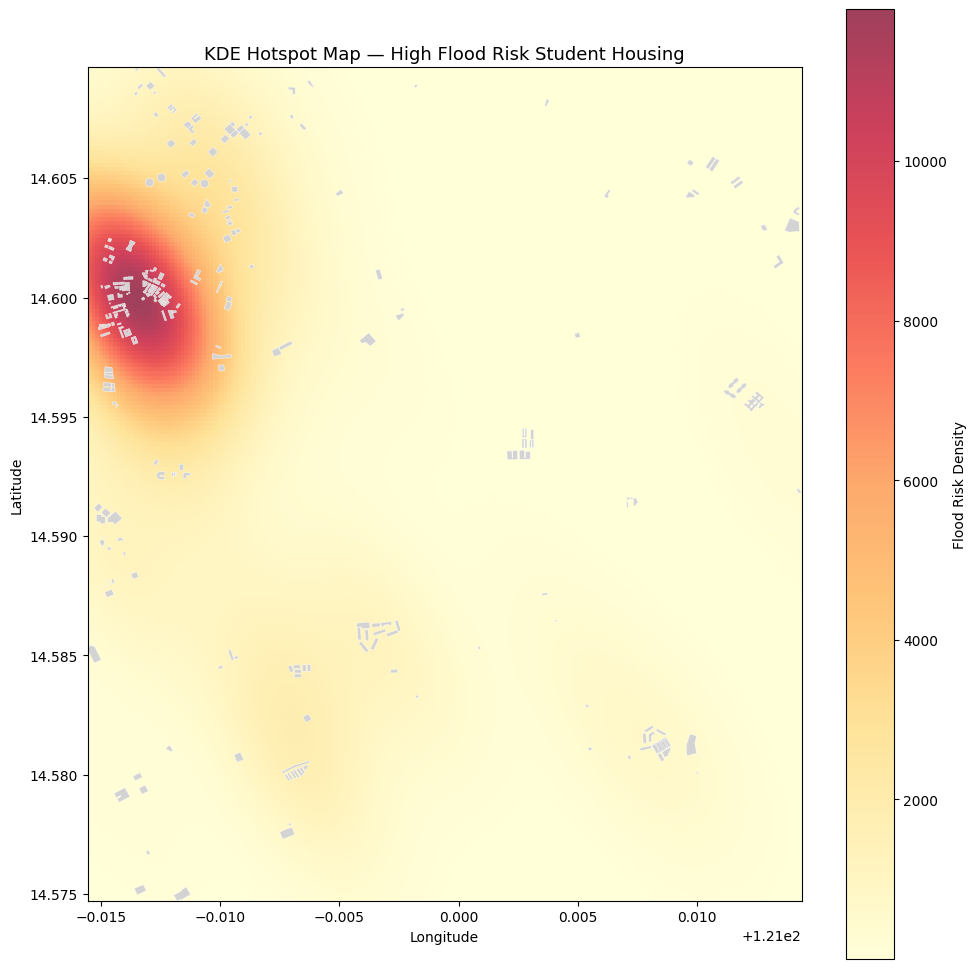

KDE hotspot map saved to outputs/hotspot_kde.png


In [7]:
# ── KDE on high-risk buildings ──
from scipy.stats import gaussian_kde

high_risk = housing_flood[housing_flood["risk_class"] == "High Risk"].copy()
print(f"High-risk buildings for KDE: {len(high_risk)}")

# Use centroids in WGS84 for coordinate extraction
high_risk_wgs = high_risk.to_crs(epsg=4326)
coords = np.array([
    [geom.centroid.x, geom.centroid.y]
    for geom in high_risk_wgs.geometry
])

if len(coords) >= 2:
    kde = gaussian_kde(coords.T)

    # Evaluation grid
    all_wgs = housing_flood.to_crs(epsg=4326)
    xmin, ymin, xmax, ymax = all_wgs.total_bounds
    xx, yy = np.mgrid[xmin:xmax:200j, ymin:ymax:200j]
    positions = np.vstack([xx.ravel(), yy.ravel()])
    density = kde(positions).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(10, 10))
    all_wgs.plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.3, label="All housing")
    img = ax.imshow(
        density.T, origin="lower",
        extent=[xmin, xmax, ymin, ymax],
        cmap="YlOrRd", alpha=0.75
    )
    plt.colorbar(img, ax=ax, label="Flood Risk Density")
    ax.set_title("KDE Hotspot Map — High Flood Risk Student Housing", fontsize=13)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.tight_layout()
    plt.savefig("outputs/hotspot_kde.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("KDE hotspot map saved to outputs/hotspot_kde.png")
else:
    print("Not enough high-risk buildings for KDE. Check risk classification.")

### Getis-Ord Gi*

KDE is good for visualisation but it doesn't tell us whether a cluster is statistically significant. Getis-Ord Gi* does, it calculates a z-score for each grid cell based on how its risk score compares to its neighbours. A z-score above 1.96 means the cluster is significant at the 95% confidence level and we call it a Hot Spot. We use a 400m neighbourhood threshold, which covers the two cells immediately surrounding each cell.

In [8]:
# ── Getis-Ord Gi* on grid cells ──
# Uses average risk score per 200m cell

from scipy.spatial import cKDTree

# Work on cells that have at least one building
grid_active = grid[grid["building_count"] > 0].copy().reset_index(drop=True)

# Get centroids
centroids = np.array([
    [geom.centroid.x, geom.centroid.y]
    for geom in grid_active.geometry
])

values = grid_active["avg_risk_score"].values
n = len(values)
global_mean = values.mean()
global_std = values.std()

# Build spatial weights using 400m threshold (2 cells)
tree = cKDTree(centroids)
threshold = 400

gi_scores = []
for i, pt in enumerate(centroids):
    neighbors = tree.query_ball_point(pt, threshold)
    w = np.zeros(n)
    w[neighbors] = 1
    w[i] = 0  # exclude self

    wi_sum = w.sum()
    if wi_sum == 0:
        gi_scores.append(0)
        continue

    numerator = (w * values).sum() - global_mean * wi_sum
    s = np.sqrt((values ** 2).mean() - global_mean ** 2)
    denominator = s * np.sqrt(
        (n * (w ** 2).sum() - wi_sum ** 2) / (n - 1)
    ) if s > 0 else 1

    gi_scores.append(numerator / denominator if denominator != 0 else 0)

grid_active["gi_z_score"] = gi_scores

# Classify hotspots: z > 1.96 = significant at 95% confidence
grid_active["hotspot_class"] = pd.cut(
    grid_active["gi_z_score"],
    bins=[-np.inf, -1.96, 1.96, np.inf],
    labels=["Cold Spot", "Not Significant", "Hot Spot"]
)

print("Getis-Ord Gi* results:")
print(grid_active["hotspot_class"].value_counts())

# Merge back to full grid
grid = grid.merge(
    grid_active[["cell_id", "gi_z_score", "hotspot_class"]],
    on="cell_id", how="left"
)
grid.to_file("data/processed/density_grid_risk.geojson", driver="GeoJSON")
print("Grid with Gi* scores saved.")

Getis-Ord Gi* results:
hotspot_class
Not Significant    82
Cold Spot          10
Hot Spot            4
Name: count, dtype: int64
Grid with Gi* scores saved.


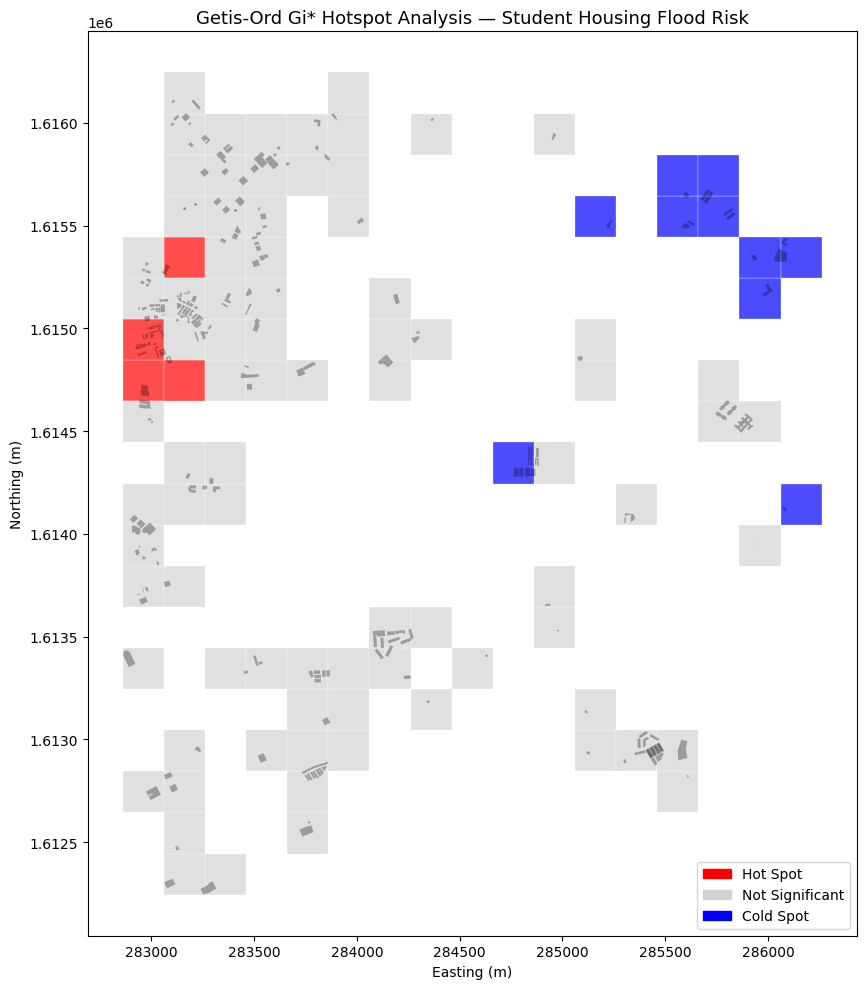

Getis-Ord Gi* map saved to outputs/hotspot_gistar.png


In [9]:
# ── Plot Getis-Ord Gi* hotspot map ──
fig, ax = plt.subplots(figsize=(10, 10))

color_map = {"Hot Spot": "red", "Not Significant": "lightgrey", "Cold Spot": "blue"}

for label, color in color_map.items():
    subset = grid_active[grid_active["hotspot_class"] == label]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, alpha=0.7, label=label, edgecolor="white", linewidth=0.3)

housing_flood.to_crs(epsg=32651).plot(ax=ax, color="black", markersize=1, alpha=0.3)

patches = [mpatches.Patch(color=c, label=l) for l, c in color_map.items()]
ax.legend(handles=patches, loc="lower right")
ax.set_title("Getis-Ord Gi* Hotspot Analysis — Student Housing Flood Risk", fontsize=13)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.savefig("outputs/hotspot_gistar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Getis-Ord Gi* map saved to outputs/hotspot_gistar.png")

## 03 Road Accessibility Under Flood Conditions

The final analysis asks a practical question: if flooding hits, can students in high-risk housing still get to their university? To answer this, we simulate a flood scenario by removing road segments that fall inside medium or high hazard zones from the road network graph. We then run shortest-path routing on what remains and check whether each high-risk housing building can still reach at least one university.

In [10]:
# ── Flag road segments in medium/high flood zones ──
edges_proj = edges.to_crs(epsg=32651)
flood_medium_high = flood_clipped[flood_clipped["hazard_level"].isin(["medium", "high"])].to_crs(epsg=32651)

flooded_edges = gpd.sjoin(
    edges_proj,
    flood_medium_high[["geometry", "hazard_level"]],
    how="inner",
    predicate="intersects"
)

print(f"Total road segments: {len(edges)}")
print(f"Road segments in medium/high flood zones: {len(flooded_edges)}")
print(f"Percentage flooded: {100*len(flooded_edges)/len(edges):.1f}%")

# Save flagged roads
flooded_edges.to_file("data/processed/flooded_roads.geojson", driver="GeoJSON")
print("Flooded roads saved.")

Total road segments: 3599
Road segments in medium/high flood zones: 3154
Percentage flooded: 87.6%
Flooded roads saved.


### Building the Flooded Road Graph

We take the full road network graph from OSMnx and remove every edge (road segment) that intersects a medium or high flood hazard zone. What's left is a graph that only contains roads we'd expect to still be passable during the flood scenario. In our study area, 87.6% of road segments are flagged as flooded under the 100-year return period map, which means the remaining usable network is quite limited.

In [11]:
# ── Build flooded road graph ──
# Get u/v node pairs of flooded edges
flooded_edge_ids = set(zip(flooded_edges["u"], flooded_edges["v"]))

# Copy graph and remove flooded edges
G_flooded = G.copy()
edges_to_remove = [
    (u, v, k) for u, v, k in G.edges(keys=True)
    if (u, v) in flooded_edge_ids
]
G_flooded.remove_edges_from(edges_to_remove)

print(f"Original graph edges: {G.number_of_edges()}")
print(f"Flooded graph edges: {G_flooded.number_of_edges()}")
print(f"Edges removed: {G.number_of_edges() - G_flooded.number_of_edges()}")

Original graph edges: 3599
Flooded graph edges: 645
Edges removed: 2954


### Routing Check

For each high-risk housing building, we find its nearest node in the road graph and try to find a shortest path to the nearest node of every university — first on the full network, then on the flooded network. If no path exists on the flooded network to any university at all, that building is marked as cut off.

In [12]:
# ── Check accessibility from high-risk housing to universities ──
high_risk_housing = housing_flood[housing_flood["risk_class"] == "High Risk"].copy()
high_risk_housing = high_risk_housing.to_crs(epsg=4326)
universities_wgs = universities.to_crs(epsg=4326)

# Get nearest graph node for each high-risk housing centroid
housing_nodes = [
    ox.nearest_nodes(G, row.geometry.centroid.x, row.geometry.centroid.y)
    for _, row in high_risk_housing.iterrows()
]

# Get nearest graph node for each university
# Use only polygon/point universities with valid centroids
uni_nodes = []
uni_names = []
for _, row in universities_wgs.iterrows():
    try:
        centroid = row.geometry.centroid
        node = ox.nearest_nodes(G, centroid.x, centroid.y)
        uni_nodes.append(node)
        uni_names.append(row.get("name", "Unknown"))
    except Exception:
        continue

print(f"High-risk housing buildings: {len(housing_nodes)}")
print(f"University nodes: {len(uni_nodes)}")

High-risk housing buildings: 180
University nodes: 60


### Identifying Cut-Off Buildings

We collect the routing results into a GeoDataFrame. Each high-risk building gets a `cut_off` flag — `True` if it has no usable route to any university under flood conditions, `False` if at least one route still exists. We also record which universities are still reachable for buildings that aren't fully cut off.

In [13]:
# ── Identify cut-off housing areas ──
results = []

for i, (h_node, (_, h_row)) in enumerate(zip(housing_nodes, high_risk_housing.iterrows())):
    can_reach_any = False
    reachable_unis = []

    for u_node, u_name in zip(uni_nodes, uni_names):
        # Check normal network
        try:
            path_normal = nx.shortest_path(G, h_node, u_node, weight="length")
            normal_accessible = True
        except nx.NetworkXNoPath:
            normal_accessible = False

        # Check flooded network
        try:
            path_flooded = nx.shortest_path(G_flooded, h_node, u_node, weight="length")
            flood_accessible = True
            can_reach_any = True
            reachable_unis.append(u_name)
        except nx.NetworkXNoPath:
            flood_accessible = False

    results.append({
        "geometry": h_row.geometry,
        "risk_score": h_row["risk_score"],
        "risk_class": h_row["risk_class"],
        "hazard_level": h_row["hazard_level"],
        "can_reach_university": can_reach_any,
        "reachable_universities": ", ".join(reachable_unis) if reachable_unis else "None",
        "cut_off": not can_reach_any
    })

accessibility_gdf = gpd.GeoDataFrame(results, crs=high_risk_housing.crs)

print("Accessibility results:")
print(f"  High-risk buildings checked: {len(accessibility_gdf)}")
print(f"  Can reach a university during flood: {accessibility_gdf['can_reach_university'].sum()}")
print(f"  Cut off from all universities: {accessibility_gdf['cut_off'].sum()}")

accessibility_gdf.to_file("data/processed/accessibility_results.geojson", driver="GeoJSON")
print("Accessibility results saved.")

Accessibility results:
  High-risk buildings checked: 180
  Can reach a university during flood: 23
  Cut off from all universities: 157
Accessibility results saved.


## Output Maps

The following cells produce all the static maps saved to the `outputs/` folder. Each map is also included in the final interactive Folium web map below.

### Map 1: Composite Flood Risk Index by Building

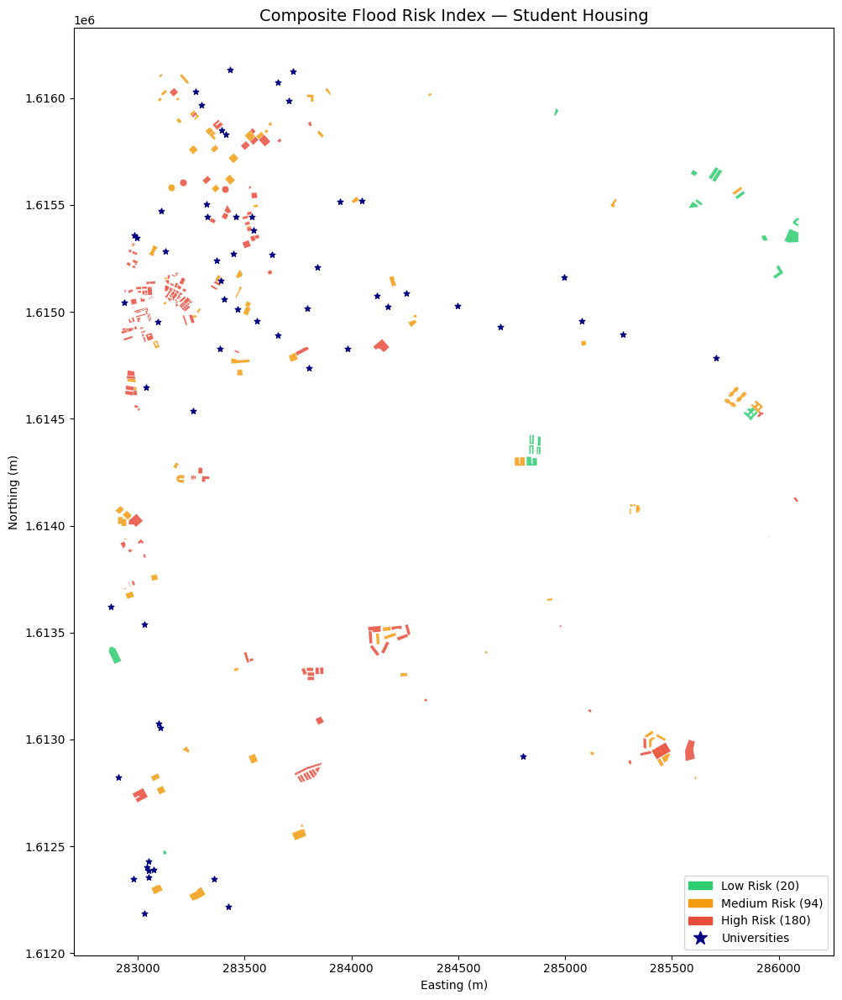

Composite risk map saved.


In [14]:
# Map 1: Composite flood risk index by building
fig, ax = plt.subplots(figsize=(12, 12))

import matplotlib.lines as mlines

color_risk = {
    "Low Risk": "#2ecc71",
    "Medium Risk": "#f39c12",
    "High Risk": "#e74c3c"
}

housing_flood["risk_class_str"] = housing_flood["risk_class"].astype(str)

for risk_class, color in color_risk.items():
    subset = housing_flood[housing_flood["risk_class_str"] == risk_class]
    subset.plot(ax=ax, color=color, edgecolor="white",
               linewidth=0.2, alpha=0.85)

universities_proj = universities.to_crs(epsg=32651)
uni_centroids = universities_proj.copy()
uni_centroids["geometry"] = universities_proj.geometry.centroid
uni_centroids.plot(ax=ax, color="navy", markersize=25,
                  marker="*", zorder=5)

low_n = (housing_flood["risk_class_str"] == "Low Risk").sum()
med_n = (housing_flood["risk_class_str"] == "Medium Risk").sum()
high_n = (housing_flood["risk_class_str"] == "High Risk").sum()

legend_handles = [
    mpatches.Patch(color="#2ecc71", label=f"Low Risk ({low_n})"),
    mpatches.Patch(color="#f39c12", label=f"Medium Risk ({med_n})"),
    mpatches.Patch(color="#e74c3c", label=f"High Risk ({high_n})"),
    mlines.Line2D([], [], color="navy", marker="*", linestyle="None", markersize=12, label="Universities"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=10)
ax.set_title("Composite Flood Risk Index — Student Housing", fontsize=14)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.savefig("outputs/map_composite_risk.png", dpi=150, bbox_inches="tight")
plt.show()
print("Composite risk map saved.")

### Map 2: Flood Hazard Exposure

This map shows each student housing building coloured by which flood hazard zone it falls in (low, medium, or high from the Project NOAH 100-year return period data). The blue background shows the extent of the flood hazard zones across the study area.

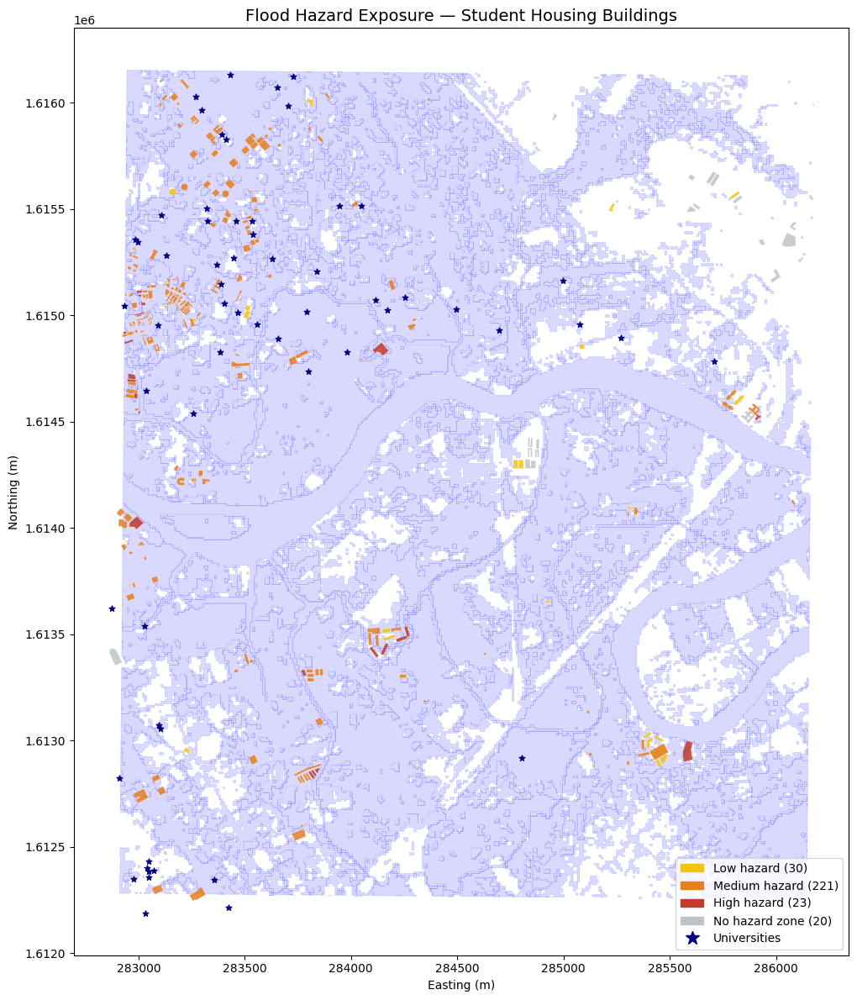

Hazard exposure map saved.


In [15]:
#  Map 2: Flood hazard exposure map 
fig, ax = plt.subplots(figsize=(12, 12))

import matplotlib.lines as mlines

hazard_colors = {
    "low": "#f1c40f",
    "medium": "#e67e22",
    "high": "#c0392b",
    "none": "#bdc3c7"
}

flood_clipped.to_crs(epsg=32651).plot(
    ax=ax, alpha=0.15, color="blue",
    edgecolor="blue", linewidth=0.5)

for level, color in hazard_colors.items():
    subset = housing_flood[housing_flood["hazard_level"] == level]
    if len(subset) > 0:
        subset.plot(ax=ax, color=color, edgecolor="white",
                   linewidth=0.2, alpha=0.85)

universities_proj = universities.to_crs(epsg=32651)
uni_centroids = universities_proj.copy()
uni_centroids["geometry"] = universities_proj.geometry.centroid
uni_centroids.plot(ax=ax, color="navy", markersize=25,
                  marker="*", zorder=5)

low_n = (housing_flood["hazard_level"] == "low").sum()
med_n = (housing_flood["hazard_level"] == "medium").sum()
high_n = (housing_flood["hazard_level"] == "high").sum()
none_n = (housing_flood["hazard_level"] == "none").sum()

legend_handles = [
    mpatches.Patch(color="#f1c40f", label=f"Low hazard ({low_n})"),
    mpatches.Patch(color="#e67e22", label=f"Medium hazard ({med_n})"),
    mpatches.Patch(color="#c0392b", label=f"High hazard ({high_n})"),
    mpatches.Patch(color="#bdc3c7", label=f"No hazard zone ({none_n})"),
    mlines.Line2D([], [], color="navy", marker="*", linestyle="None", markersize=12, label="Universities"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=10)
ax.set_title("Flood Hazard Exposure — Student Housing Buildings", fontsize=14)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.savefig("outputs/map_hazard_exposure.png", dpi=150, bbox_inches="tight")
plt.show()
print("Hazard exposure map saved.")

### Map 3: Road Accessibility

This map shows the road network under flood conditions. Grey roads are still passable; red roads are flooded. Housing buildings are coloured green if they can still reach a university and purple if they are completely cut off.

c:\Users\Chrysille So\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


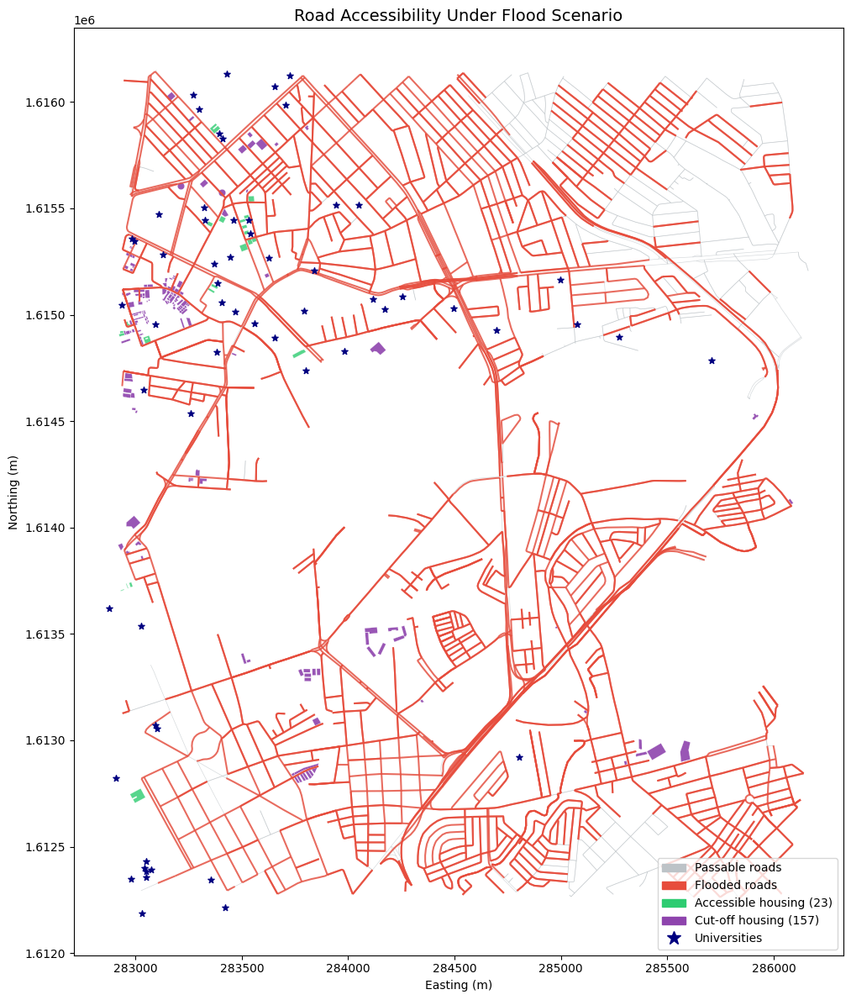

Road accessibility map saved.


In [16]:
# Map 3: Road accessibility: normal vs. flood scenario
fig, ax = plt.subplots(figsize=(12, 12))

import matplotlib.lines as mlines

edges_proj = edges.to_crs(epsg=32651)
flooded_roads = gpd.read_file("data/processed/flooded_roads.geojson")

cutoff = accessibility_gdf[accessibility_gdf["cut_off"] == True].to_crs(epsg=32651)
accessible = accessibility_gdf[accessibility_gdf["cut_off"] == False].to_crs(epsg=32651)

edges_proj.plot(ax=ax, color="#bdc3c7", linewidth=0.5, alpha=0.6)

flooded_roads.to_crs(epsg=32651).plot(ax=ax, color="#e74c3c",
                                       linewidth=1.5, alpha=0.8)

if len(accessible) > 0:
    accessible.plot(ax=ax, color="#2ecc71", edgecolor="white",
                   linewidth=0.2, alpha=0.8)
if len(cutoff) > 0:
    cutoff.plot(ax=ax, color="#8e44ad", edgecolor="white",
               linewidth=0.2, alpha=0.9)

universities_proj = universities.to_crs(epsg=32651)
uni_centroids = universities_proj.copy()
uni_centroids["geometry"] = universities_proj.geometry.centroid
uni_centroids.plot(ax=ax, color="navy", markersize=30,
                  marker="*", zorder=5)

legend_handles = [
    mpatches.Patch(color="#bdc3c7", label="Passable roads"),
    mpatches.Patch(color="#e74c3c", label="Flooded roads"),
    mpatches.Patch(color="#2ecc71", label=f"Accessible housing ({len(accessible)})"),
    mpatches.Patch(color="#8e44ad", label=f"Cut-off housing ({len(cutoff)})"),
    mlines.Line2D([], [], color="navy", marker="*", linestyle="None", markersize=12, label="Universities"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=10)
ax.set_title("Road Accessibility Under Flood Scenario", fontsize=14)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
plt.savefig("outputs/map_road_accessibility.png", dpi=150, bbox_inches="tight")
plt.show()
print("Road accessibility map saved.")

## Interactive Web Map

The Folium map combines all layers into one interactive HTML file. You can toggle each layer on and off using the layer control in the top right. Hover over any housing building to see its risk score, hazard level, and floor count. If the map shows 'Make this Notebook Trusted', run `python -m jupyter trust 02_composite_risk_index.ipynb` in your VS Code terminal and reopen the notebook.

In [17]:
# ── Interactive Folium map combining all layers ──
import folium
from folium.plugins import HeatMap

# Center on study area
m = folium.Map(location=[14.5925, 121.0000], zoom_start=14, tiles="CartoDB positron")

# Layer 1: Flood hazard zones
hazard_wgs = flood_clipped.to_crs(epsg=4326)
hazard_color_map = {"low": "#f1c40f", "medium": "#e67e22", "high": "#c0392b"}

flood_layer = folium.FeatureGroup(name="Flood Hazard Zones")
for _, row in hazard_wgs.iterrows():
    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f, color=hazard_color_map.get(row["hazard_level"], "grey"): {
            "fillColor": color, "color": color, "weight": 1, "fillOpacity": 0.3
        }
    ).add_to(flood_layer)
flood_layer.add_to(m)

# Layer 2: Student housing by risk class
housing_wgs = housing_flood.to_crs(epsg=4326)
risk_color_map = {"Low Risk": "#2ecc71", "Medium Risk": "#f39c12", "High Risk": "#e74c3c"}

housing_layer = folium.FeatureGroup(name="Student Housing (Risk)")
for _, row in housing_wgs.iterrows():
    color = risk_color_map.get(str(row.get("risk_class", "")), "grey")
    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f, c=color: {
            "fillColor": c, "color": c, "weight": 0.5, "fillOpacity": 0.8
        },
        tooltip=folium.Tooltip(
            f"Risk: {row.get('risk_class', 'N/A')}<br>"
            f"Hazard: {row.get('hazard_level', 'N/A')}<br>"
            f"Score: {row.get('risk_score', 0):.3f}<br>"
            f"Floors: {row.get('levels', 'N/A')}"
        )
    ).add_to(housing_layer)
housing_layer.add_to(m)

# Layer 3: Flooded roads
flooded_wgs = gpd.read_file("data/processed/flooded_roads.geojson").to_crs(epsg=4326)
road_layer = folium.FeatureGroup(name="Flooded Roads")
for _, row in flooded_wgs.iterrows():
    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f: {"color": "#e74c3c", "weight": 2.5, "opacity": 0.8}
    ).add_to(road_layer)
road_layer.add_to(m)

# Layer 4: Universities
uni_layer = folium.FeatureGroup(name="Universities")
universities_wgs = universities.to_crs(epsg=4326)
for _, row in universities_wgs.iterrows():
    try:
        centroid = row.geometry.centroid
        folium.Marker(
            location=[centroid.y, centroid.x],
            popup=folium.Popup(str(row.get("name", "University")), max_width=200),
            icon=folium.Icon(color="blue", icon="graduation-cap", prefix="fa")
        ).add_to(uni_layer)
    except Exception:
        continue
uni_layer.add_to(m)

# Layer 5: Cut-off housing
if "cut_off" in accessibility_gdf.columns:
    cutoff_wgs = accessibility_gdf[accessibility_gdf["cut_off"] == True].to_crs(epsg=4326)
    cutoff_layer = folium.FeatureGroup(name="Cut-off Housing (Flood Scenario)")
    for _, row in cutoff_wgs.iterrows():
        folium.GeoJson(
            row.geometry.__geo_interface__,
            style_function=lambda f: {
                "fillColor": "#8e44ad", "color": "#8e44ad",
                "weight": 1.5, "fillOpacity": 0.9
            },
            tooltip="Cut off from universities during flood"
        ).add_to(cutoff_layer)
    cutoff_layer.add_to(m)

# Add layer control
folium.LayerControl(collapsed=False).add_to(m)

# Save
m.save("outputs/interactive_map.html")
print("Interactive Folium map saved to outputs/interactive_map.html")
m

c:\Users\Chrysille So\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\io\file.py:576: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Interactive Folium map saved to outputs/interactive_map.html


## Final Summary

This cell prints a quick count of results across all steps as a sanity check before submitting. All output files are saved in the `outputs/` folder.

In [18]:
# Sanity check on final results
print("=== FINAL SUMMARY ===")
print(f"\nTotal student housing buildings: {len(housing_flood)}")
print(f"\nRisk class distribution:")
print(housing_flood["risk_class"].value_counts())
print(f"\nHazard distribution:")
print(housing_flood["hazard_level"].value_counts())
print(f"\nBuildings in flood zone: {housing_flood['in_flood_zone'].sum()}")
print(f"\nAccessibility results:")
print(f"  Cut-off from all universities: {accessibility_gdf['cut_off'].sum()}")
print(f"  Can reach at least one university: {(~accessibility_gdf['cut_off']).sum()}")
print(f"\nOutputs saved:")
import os
for f in os.listdir("outputs"):
    print(f"  outputs/{f}")

=== FINAL SUMMARY ===

Total student housing buildings: 294

Risk class distribution:
risk_class
High Risk      180
Medium Risk     94
Low Risk        20
Name: count, dtype: int64

Hazard distribution:
hazard_level
medium    221
low        30
high       23
none       20
Name: count, dtype: int64

Buildings in flood zone: 274

Accessibility results:
  Cut-off from all universities: 157
  Can reach at least one university: 23

Outputs saved:
  outputs/hotspot_gistar.png
  outputs/hotspot_kde.png
  outputs/interactive_map.html
  outputs/map_composite_risk.png
  outputs/map_hazard_exposure.png
  outputs/map_road_accessibility.png
